# Model training v3 (feature selection, stronger regularization, permutation importance)
Reads `../data/final_model_ready_cart_events_v2.csv` (read only). Nothing from earlier notebooks or files is overwritten.

Steps: rank features with a quick model, keep the top K, retrain with shallower trees and larger leaves, check the train/validation gap, tune thresholds on validation, report on test, and show permutation importance.

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             log_loss, ConfusionMatrixDisplay)
from xgboost import XGBClassifier
import shap

# ---- Settings you can change ----
KEEP_TOP_K = 40               # keep this many features (the rest are dropped)
DROP_TIME_FEATURES = False    # True removes calendar features that will not generalize to a new period
TIME_FEATURES = ["cart_day_of_year", "days_since_first_event"]


In [2]:
# Read-only: loads the v2 file, nothing is overwritten
df = pd.read_csv("../data/final_model_ready_cart_events_v2.csv")
usable = (~df["censored"]) & (~df["heavy_session"]) & (~df["heavy_user"])
df = df[usable].reset_index(drop=True)

TARGET = "is_abandoned"
DROP_COLS = ["is_abandoned", "outcome", "quick_remove", "removed_then_rebought",
             "censored", "heavy_session", "heavy_user", "row_id", "session_id",
             "category_id", "event_time", "user_id"]
DROP_COLS = [c for c in DROP_COLS if c in df.columns]

X = df.drop(columns=DROP_COLS)
if DROP_TIME_FEATURES:
    X = X.drop(columns=[c for c in TIME_FEATURES if c in X.columns])
y = df[TARGET].astype(int)
groups = df["user_id"]
print("Rows:", len(X), "| Features:", X.shape[1])


Rows: 3173126 | Features: 60


In [3]:
# Same three-way split by user as before: train 64% / validation 16% / test 20%
gss_test = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
trainval_idx, test_idx = next(gss_test.split(X, y, groups=groups))
gss_val = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=7)
tr_rel, val_rel = next(gss_val.split(X.iloc[trainval_idx], y.iloc[trainval_idx],
                                     groups=groups.iloc[trainval_idx]))
train_idx, val_idx = trainval_idx[tr_rel], trainval_idx[val_rel]

y_train, y_val, y_test = y.iloc[train_idx], y.iloc[val_idx], y.iloc[test_idx]
mon_idx = np.random.default_rng(42).choice(len(train_idx), min(300_000, len(train_idx)), replace=False)
print("Train:", len(train_idx), "| Val:", len(val_idx), "| Test:", len(test_idx))


Train: 2035400 | Val: 507423 | Test: 630303


In [4]:
# Stage 1: quick model on all features, only to rank them (uses train + validation, never test)
rank_model = XGBClassifier(n_estimators=400, learning_rate=0.1, max_depth=6, min_child_weight=50,
                           subsample=0.8, colsample_bytree=0.7, tree_method="hist",
                           eval_metric="auc", early_stopping_rounds=30, n_jobs=-1, random_state=42)
rank_model.fit(X.iloc[train_idx], y_train, eval_set=[(X.iloc[val_idx], y_val)], verbose=False)

ranking = pd.Series(rank_model.feature_importances_, index=X.columns).sort_values(ascending=False)
k = min(KEEP_TOP_K, len(ranking))
selected = ranking.index[:k].tolist()
print(f"Keeping {k} of {len(ranking)} features")
print("Dropped:", ranking.index[k:].tolist())

X_train, X_val, X_test = (X.iloc[train_idx][selected], X.iloc[val_idx][selected], X.iloc[test_idx][selected])
X_mon, y_mon = X_train.iloc[mon_idx], y_train.iloc[mon_idx]


Keeping 40 of 60 features
Dropped: ['events_in_session_before', 'cart_items_net', 'purchases_before_in_session', 'userprod_prior_remove_rate', 'previous_sessions', 'user_prior_view_to_cart', 'cat_prior_view_to_cart', 'user_prior_views', 'cart_day_of_week', 'brand_switch_count_before_cart', 'category_avg_price', 'cat_prior_views', 'cat_prior_purchases', 'cart_brand_is_real', 'price_ratio_to_category', 'cat_prior_carts', 'price_vs_category_avg', 'cat_prior_removes', 'prod_prior_removes', 'price_change_since_view']


In [5]:
# Stage 2: final model with stronger regularization (shallower trees, bigger leaves)
model = XGBClassifier(
    n_estimators=3000,
    learning_rate=0.05,
    max_depth=5,              # was 7
    min_child_weight=200,     # was 50
    subsample=0.8,
    colsample_bytree=0.7,
    reg_lambda=10,
    reg_alpha=1,
    tree_method="hist",
    eval_metric=["logloss", "auc"],   # early stopping uses AUC on the last eval set (validation)
    early_stopping_rounds=100,
    n_jobs=-1,
    random_state=42,
)
model.fit(X_train, y_train, eval_set=[(X_mon, y_mon), (X_val, y_val)], verbose=100)
print("Best iteration:", model.best_iteration)


[0]	validation_0-logloss:0.58070	validation_0-auc:0.62290	validation_1-logloss:0.58550	validation_1-auc:0.62286
[100]	validation_0-logloss:0.52701	validation_0-auc:0.70454	validation_1-logloss:0.53323	validation_1-auc:0.70049
[200]	validation_0-logloss:0.52156	validation_0-auc:0.71216	validation_1-logloss:0.52966	validation_1-auc:0.70527
[300]	validation_0-logloss:0.51854	validation_0-auc:0.71660	validation_1-logloss:0.52826	validation_1-auc:0.70721
[400]	validation_0-logloss:0.51625	validation_0-auc:0.72012	validation_1-logloss:0.52754	validation_1-auc:0.70826
[500]	validation_0-logloss:0.51442	validation_0-auc:0.72294	validation_1-logloss:0.52724	validation_1-auc:0.70870
[600]	validation_0-logloss:0.51288	validation_0-auc:0.72525	validation_1-logloss:0.52701	validation_1-auc:0.70905
[700]	validation_0-logloss:0.51140	validation_0-auc:0.72749	validation_1-logloss:0.52688	validation_1-auc:0.70921
[800]	validation_0-logloss:0.51002	validation_0-auc:0.72957	validation_1-logloss:0.52693	v

                ROC-AUC  PR-AUC  LogLoss
Train (sample)   0.7281  0.8745   0.5111
Validation       0.7093  0.8611   0.5269
Test             0.7085  0.8611   0.5262

AUC gap (train - validation): 0.0188 (previous v2 model: 0.0476)
Rule of thumb: gap below about 0.02-0.03 = good fit | large gap = overfit | both low = underfit


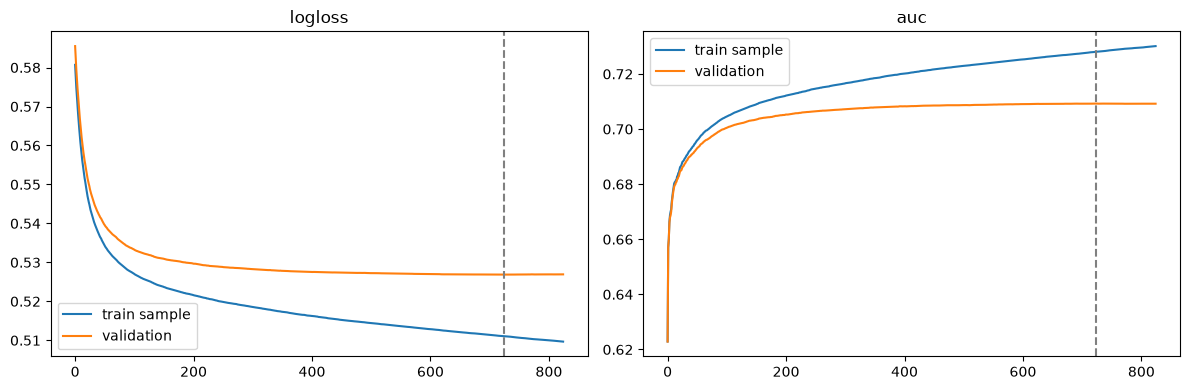

In [6]:
# Good-fit check
def split_scores(Xs, ys):
    prob = model.predict_proba(Xs)[:, 1]
    return {"ROC-AUC": roc_auc_score(ys, prob),
            "PR-AUC": average_precision_score(ys, prob),
            "LogLoss": log_loss(ys, prob)}

fit_table = pd.DataFrame({"Train (sample)": split_scores(X_mon, y_mon),
                          "Validation": split_scores(X_val, y_val),
                          "Test": split_scores(X_test, y_test)}).T.round(4)
print(fit_table)
gap = fit_table.loc["Train (sample)", "ROC-AUC"] - fit_table.loc["Validation", "ROC-AUC"]
print("\nAUC gap (train - validation):", round(gap, 4), "(previous v2 model: 0.0476)")
print("Rule of thumb: gap below about 0.02-0.03 = good fit | large gap = overfit | both low = underfit")

hist = model.evals_result()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for i, metric in enumerate(["logloss", "auc"]):
    ax[i].plot(hist["validation_0"][metric], label="train sample")
    ax[i].plot(hist["validation_1"][metric], label="validation")
    ax[i].axvline(model.best_iteration, color="gray", linestyle="--")
    ax[i].set_title(metric)
    ax[i].legend()
plt.tight_layout()
plt.show()


In [7]:
# Choose thresholds on VALIDATION only
val_prob = model.predict_proba(X_val)[:, 1]

def sweep(y_true, prob, thresholds):
    out = []
    for t in thresholds:
        pred = (prob >= t).astype(int)
        out.append({"threshold": round(t, 2),
                    "Accuracy %": accuracy_score(y_true, pred) * 100,
                    "Precision %": precision_score(y_true, pred, zero_division=0) * 100,
                    "Recall %": recall_score(y_true, pred) * 100,
                    "F1 %": f1_score(y_true, pred) * 100})
    return pd.DataFrame(out)

grid = sweep(y_val, val_prob, np.arange(0.30, 0.91, 0.02))
t_f1 = float(grid.loc[grid["F1 %"].idxmax(), "threshold"])
t_acc = float(grid.loc[grid["Accuracy %"].idxmax(), "threshold"])
print("Best threshold for F1:", t_f1, "| for Accuracy:", t_acc)
print(grid.round(2).to_string(index=False))


Best threshold for F1: 0.42 | for Accuracy: 0.5
 threshold  Accuracy %  Precision %  Recall %  F1 %
      0.30       73.29        73.26     99.48 84.38
      0.32       73.38        73.37     99.34 84.40
      0.34       73.51        73.53     99.16 84.44
      0.36       73.65        73.71     98.94 84.48
      0.38       73.77        73.91     98.67 84.51
      0.40       73.91        74.13     98.32 84.53
      0.42       74.04        74.39     97.91 84.54
      0.44       74.15        74.67     97.40 84.53
      0.46       74.24        74.97     96.80 84.50
      0.48       74.32        75.31     96.10 84.44
      0.50       74.37        75.69     95.25 84.35
      0.52       74.33        76.07     94.24 84.19
      0.54       74.25        76.49     93.09 83.98
      0.56       74.07        76.96     91.69 83.68
      0.58       73.81        77.47     90.08 83.30
      0.60       73.41        78.02     88.17 82.78
      0.62       72.83        78.59     85.96 82.11
      0.64      

Baseline (always Abandoned): Accuracy 72.61 | F1 84.13
ROC-AUC: 70.85 (v2: 71.15) | PR-AUC: 86.11 (v2: 86.29)

Best F1 threshold (0.42): Acc 74.13 | Prec 74.44 | Rec 98.04 | F1 84.62
Best Accuracy threshold (0.5): Acc 74.43 | Prec 75.69 | Rec 95.42 | F1 84.42
Default 0.5 (0.5): Acc 74.43 | Prec 75.69 | Rec 95.42 | F1 84.42

v2 reference: Acc 74.44 (thr 0.48) | F1 84.63 (thr 0.42)


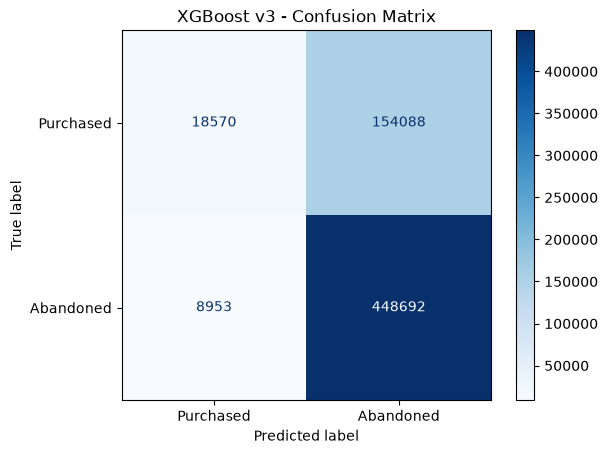

In [8]:
# Final report on TEST, compared with the earlier 60-feature model (v2)
test_prob = model.predict_proba(X_test)[:, 1]
base_acc = max(y_test.mean(), 1 - y_test.mean()) * 100
print(f"Baseline (always Abandoned): Accuracy {base_acc:.2f} | F1 {f1_score(y_test, np.ones(len(y_test), int)) * 100:.2f}")
print(f"ROC-AUC: {roc_auc_score(y_test, test_prob) * 100:.2f} (v2: 71.15) | "
      f"PR-AUC: {average_precision_score(y_test, test_prob) * 100:.2f} (v2: 86.29)\n")

for label, t in [("Best F1 threshold", t_f1), ("Best Accuracy threshold", t_acc), ("Default 0.5", 0.5)]:
    pred = (test_prob >= t).astype(int)
    print(f"{label} ({t}): "
          f"Acc {accuracy_score(y_test, pred) * 100:.2f} | "
          f"Prec {precision_score(y_test, pred) * 100:.2f} | "
          f"Rec {recall_score(y_test, pred) * 100:.2f} | "
          f"F1 {f1_score(y_test, pred) * 100:.2f}")
print("\nv2 reference: Acc 74.44 (thr 0.48) | F1 84.63 (thr 0.42)")

pred = (test_prob >= t_f1).astype(int)
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Purchased", "Abandoned"], cmap="Blues")
plt.title("XGBoost v3 - Confusion Matrix")
plt.show()


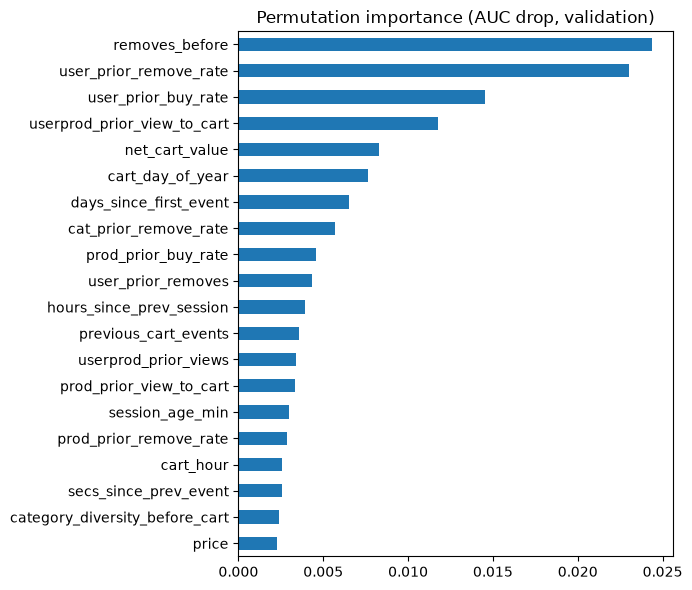

removes_before                 0.0244
user_prior_remove_rate         0.0230
user_prior_buy_rate            0.0145
userprod_prior_view_to_cart    0.0118
net_cart_value                 0.0083
cart_day_of_year               0.0076
days_since_first_event         0.0065
cat_prior_remove_rate          0.0057
prod_prior_buy_rate            0.0046
user_prior_removes             0.0043
dtype: float64


In [9]:
# Permutation importance on a validation sample: how much does AUC drop when a feature is shuffled?
samp = np.random.default_rng(0).choice(len(X_val), min(100_000, len(X_val)), replace=False)
perm = permutation_importance(model, X_val.iloc[samp], y_val.iloc[samp],
                              scoring="roc_auc", n_repeats=3, random_state=0, n_jobs=1)
perm_imp = pd.Series(perm.importances_mean, index=X_val.columns).sort_values(ascending=False)
perm_imp.head(20)[::-1].plot(kind="barh", figsize=(7, 6), title="Permutation importance (AUC drop, validation)")
plt.tight_layout()
plt.show()
print(perm_imp.round(4).head(10))


In [13]:
# Decision threshold (0.5 is the default; 0.42 gave the best F1 on validation)
THRESHOLD = 0.5

# Predicted probabilities and class labels on the test set
y_prob = model.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= THRESHOLD).astype(int)

# Metrics
print(f"Accuracy  : {accuracy_score(y_test, y_pred) * 100:.2f} %")
print(f"Precision : {precision_score(y_test, y_pred) * 100:.2f} %")
print(f"Recall    : {recall_score(y_test, y_pred) * 100:.2f} %")
print(f"F1 Score  : {f1_score(y_test, y_pred) * 100:.2f} %")
print(f"ROC-AUC   : {roc_auc_score(y_test, y_prob) * 100:.2f} %")

Accuracy  : 74.43 %
Precision : 75.69 %
Recall    : 95.42 %
F1 Score  : 84.42 %
ROC-AUC   : 70.85 %


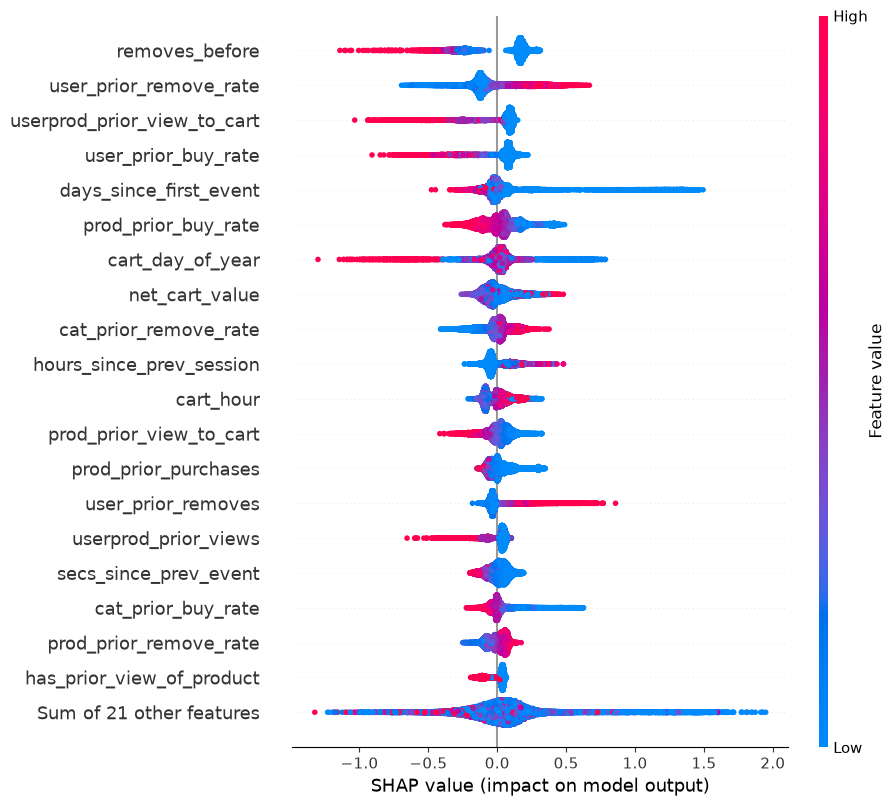

Top 15 features (mean |SHAP|):
removes_before                 0.2174
user_prior_remove_rate         0.1544
userprod_prior_view_to_cart    0.1315
user_prior_buy_rate            0.1190
days_since_first_event         0.1076
prod_prior_buy_rate            0.1009
cart_day_of_year               0.0801
net_cart_value                 0.0756
cat_prior_remove_rate          0.0735
hours_since_prev_session       0.0730
cart_hour                      0.0664
prod_prior_view_to_cart        0.0654
prod_prior_purchases           0.0593
user_prior_removes             0.0591
userprod_prior_views           0.0589
dtype: float32


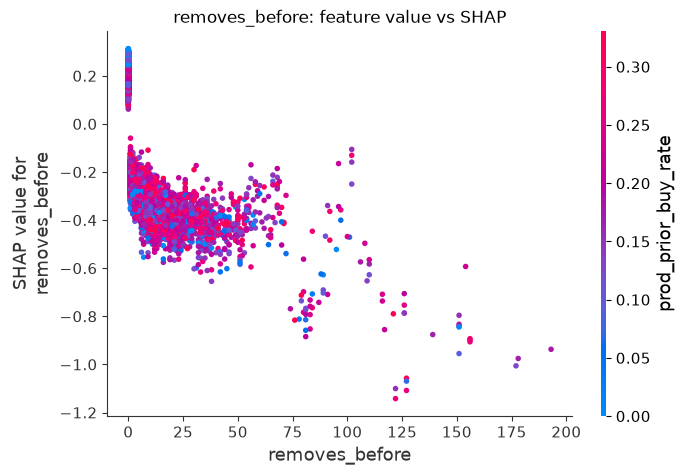

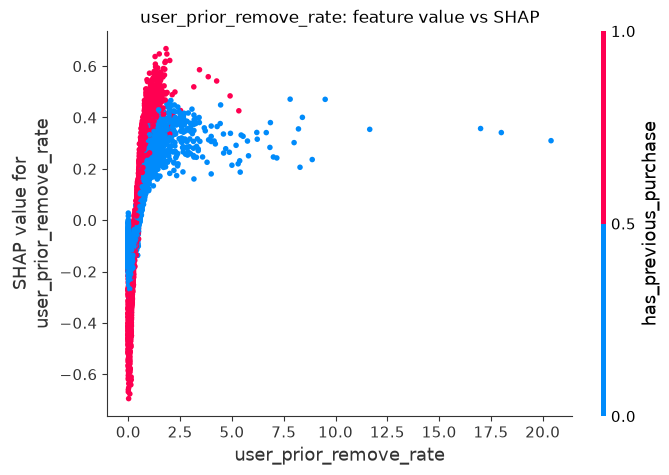

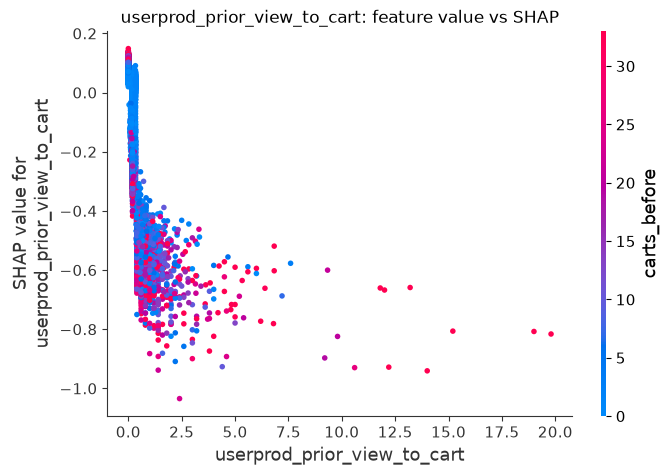

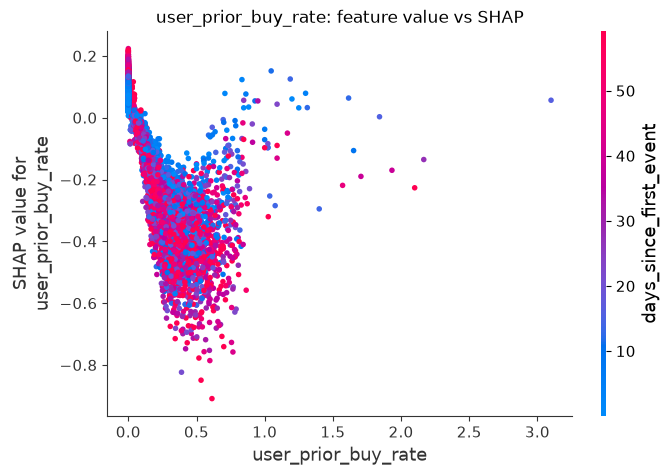

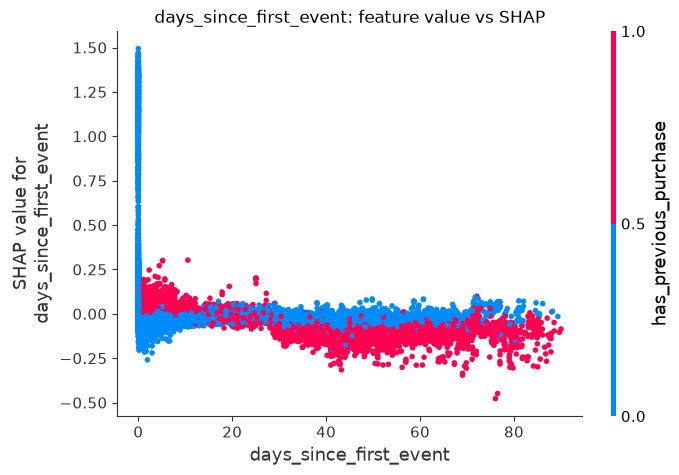

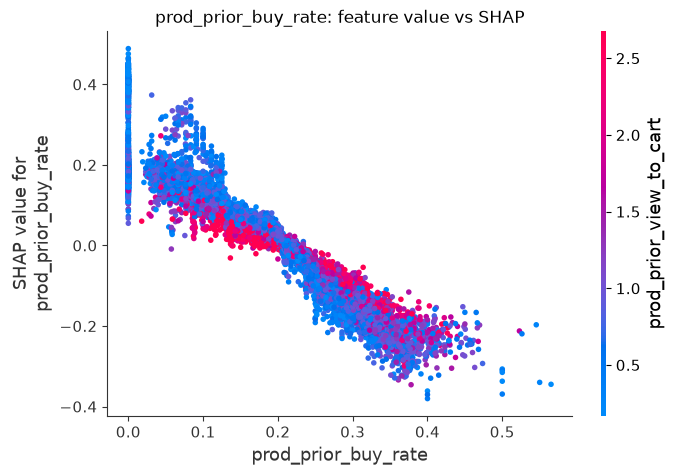


Other bucket features: ['days_since_first_event', 'cart_day_of_year']

High-risk carts (prob >= 0.8): 7232 of 20000

Main reason bucket (%):
Product / category track record    51.5
User history / trust               19.4
Other                              14.9
Low intent / hesitation             8.8
Price sensitivity                   3.6
Comparison / browsing               1.2
Timing                              0.6
Name: proportion, dtype: float64

Bucket importance (mean |SHAP|):
Product / category track record    0.3708
Low intent / hesitation            0.2407
User history / trust               0.2204
Other                              0.1604
Comparison / browsing              0.1020
Price sensitivity                  0.0915
Timing                             0.0709
dtype: float32

Sample report:
         abandon_prob                      main_reason                 feature_1                       feature_2                 feature_3
1083595         0.818  Product / category track

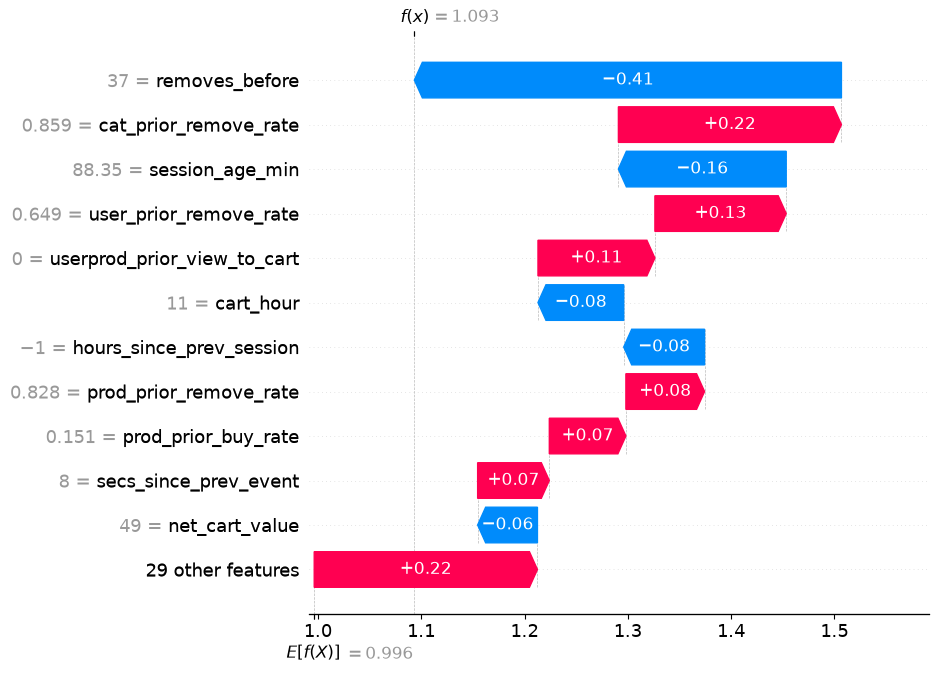

In [17]:
# ---------------------------------------------------------------
# 1) SHAP values nikalo (test set ka sample)
# ---------------------------------------------------------------
samp = X_test.sample(20_000, random_state=0)
explainer = shap.TreeExplainer(model)
sv = explainer(samp)                 # positive = Abandoned ki taraf, negative = Purchased ki taraf
vals = sv.values                     # numpy array (rows x features)
cols = np.array(samp.columns)

# ---------------------------------------------------------------
# 2) Global: kaun se features sab se zyada asar daalte hain
# ---------------------------------------------------------------
shap.plots.beeswarm(sv, max_display=20)

mean_abs = pd.Series(np.abs(vals).mean(axis=0), index=cols).sort_values(ascending=False)
print("Top 15 features (mean |SHAP|):")
print(mean_abs.head(15).round(4))

# ---------------------------------------------------------------
# 3) Top features ka direction (naam ki jagah raw arrays use ho rahe hain)
# ---------------------------------------------------------------
for f in mean_abs.head(6).index:
    shap.dependence_plot(f, vals, samp, show=False)
    plt.title(f"{f}: feature value vs SHAP")
    plt.show()

# ---------------------------------------------------------------
# 4) Features ko reason buckets mein group karo
# ---------------------------------------------------------------
def group_of(col):
    if "price" in col or col == "net_cart_value":
        return "Price sensitivity"
    if col in ["views_before_cart", "category_diversity_before_cart",
               "brand_switch_count_before_cart", "hours_since_last_view",
               "has_prior_view_of_product"]:
        return "Comparison / browsing"
    if col in ["no_view_before_cart", "removes_before", "is_first_cart_in_session",
               "session_age_min", "secs_since_prev_event", "carts_before",
               "cart_items_net", "events_in_session_before",
               "purchases_before_in_session"]:
        return "Low intent / hesitation"
    if col.startswith(("user_", "previous_", "has_previous")) or col == "hours_since_prev_session":
        return "User history / trust"
    if col.startswith(("prod_", "cat_", "userprod_")):
        return "Product / category track record"
    if col in ["cart_hour", "cart_day_of_week", "cart_is_weekend"]:
        return "Timing"
    return "Other"

mapping = pd.Series({c: group_of(c) for c in cols})
sv_df = pd.DataFrame(vals, columns=cols, index=samp.index)
group_sv = sv_df.T.groupby(mapping).sum().T      # har cart ke liye bucket-wise asar

# Kaunse features "Other" mein gaye (check karo, zarurat ho to group_of mein add karo)
print("\nOther bucket features:", mapping[mapping == "Other"].index.tolist())

# ---------------------------------------------------------------
# 5) High-risk carts ke liye main reason
# ---------------------------------------------------------------
prob = model.predict_proba(samp)[:, 1]
HIGH_RISK = 0.8
mask = prob >= HIGH_RISK
print(f"\nHigh-risk carts (prob >= {HIGH_RISK}): {mask.sum()} of {len(samp)}")

top_bucket = group_sv[mask].idxmax(axis=1)
print("\nMain reason bucket (%):")
print(top_bucket.value_counts(normalize=True).mul(100).round(1))

# Overall bucket importance (sab carts par average asar)
print("\nBucket importance (mean |SHAP|):")
print(group_sv.abs().mean().sort_values(ascending=False).round(4))

# ---------------------------------------------------------------
# 6) Har cart ke top 3 features aur reason table
# ---------------------------------------------------------------
top3 = np.argsort(-vals, axis=1)[:, :3]          # abandonment ki taraf sab se zyada push karne wale 3 features
report = pd.DataFrame({
    "abandon_prob": prob.round(3),
    "main_reason": group_sv.idxmax(axis=1).values,
    "feature_1": cols[top3[:, 0]],
    "feature_2": cols[top3[:, 1]],
    "feature_3": cols[top3[:, 2]],
}, index=samp.index)
print("\nSample report:")
print(report[mask].head(10).to_string())

# ---------------------------------------------------------------
# 7) Ek single cart ki explanation
# ---------------------------------------------------------------
shap.plots.waterfall(sv[0], max_display=12)

In [18]:
print(type(model), X_val.shape, X_test.shape, len(selected), "row_id" in df.columns)

<class 'xgboost.sklearn.XGBClassifier'> (507423, 40) (630303, 40) 40 True


In [19]:
# ===== STEP 1: Final model artifacts =====
# Run in the same notebook session where `model`, `X_val`, `X_test`, `y_val`, `y_test`,
# `selected`, `df` and `test_idx` already exist.
import json
import datetime
from pathlib import Path

import joblib
import xgboost
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import brier_score_loss

ARTIFACT_DIR = Path("../artifacts")
ARTIFACT_DIR.mkdir(exist_ok=True)

assert "row_id" in df.columns, "row_id column is required to join brand/labels later"

# 1) Raw probabilities
val_raw = model.predict_proba(X_val)[:, 1]
test_raw = model.predict_proba(X_test)[:, 1]

# 2) Calibrate on validation only (isotonic regression)
calibrator = IsotonicRegression(out_of_bounds="clip", y_min=0.0, y_max=1.0)
calibrator.fit(val_raw, y_val)
val_cal = calibrator.predict(val_raw)
test_cal = calibrator.predict(test_raw)

# 3) Calibration check on the test set (predicted vs actual abandonment rate per decile)
calib = pd.DataFrame({"pred": test_cal, "actual": y_test.to_numpy()})
calib["decile"] = pd.qcut(calib["pred"].rank(method="first"), 10, labels=False)
print("Calibration table (test):")
print(calib.groupby("decile").agg(pred=("pred", "mean"),
                                  actual=("actual", "mean"),
                                  n=("pred", "size")).round(3))

print("\nTest metrics")
print("ROC-AUC           :", round(roc_auc_score(y_test, test_cal), 4))
print("PR-AUC            :", round(average_precision_score(y_test, test_cal), 4))
print("Brier raw -> cal  :", round(brier_score_loss(y_test, test_raw), 4),
      "->", round(brier_score_loss(y_test, test_cal), 4))

# 4) Risk bands (relative to the validation score distribution)
BAND_LOW_Q, BAND_HIGH_Q = 0.40, 0.75
band_low = float(np.quantile(val_cal, BAND_LOW_Q))
band_high = float(np.quantile(val_cal, BAND_HIGH_Q))

def to_band(score):
    return np.where(score >= band_high, "High", np.where(score >= band_low, "Medium", "Low"))

bands = pd.DataFrame({"band": to_band(test_cal), "actual": y_test.to_numpy()})
print("\nActual abandonment rate per risk band (test):")
print(bands.groupby("band")["actual"].agg(["mean", "size"])
      .reindex(["Low", "Medium", "High"]).round(3))

# 5) Save everything the export script and the API will need
model.save_model(str(ARTIFACT_DIR / "model.json"))
joblib.dump(calibrator, ARTIFACT_DIR / "calibrator.joblib")
np.save(ARTIFACT_DIR / "test_row_ids.npy", df["row_id"].iloc[test_idx].to_numpy())

metadata = {
    "created_at": datetime.datetime.now().isoformat(timespec="seconds"),
    "xgboost_version": xgboost.__version__,
    "drop_time_features": bool(DROP_TIME_FEATURES),
    "features": list(selected),
    "best_iteration": int(model.best_iteration),
    "band_low": band_low,
    "band_high": band_high,
    "test_roc_auc": float(roc_auc_score(y_test, test_cal)),
    "test_pr_auc": float(average_precision_score(y_test, test_cal)),
    "test_abandon_rate": float(y_test.mean()),
}
(ARTIFACT_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2))
print("\nSaved artifacts to:", ARTIFACT_DIR.resolve())

Calibration table (test):
         pred  actual      n
decile                      
0       0.413   0.410  63031
1       0.571   0.570  63030
2       0.641   0.644  63030
3       0.696   0.692  63030
4       0.739   0.736  63031
5       0.771   0.770  63030
6       0.801   0.799  63030
7       0.833   0.830  63030
8       0.864   0.865  63030
9       0.946   0.945  63031

Test metrics
ROC-AUC           : 0.7084
PR-AUC            : 0.8597
Brier raw -> cal  : 0.1759 -> 0.1759

Actual abandonment rate per risk band (test):
         mean    size
band                 
Low     0.575  244740
Medium  0.771  216652
High    0.887  168911

Saved artifacts to: D:\Cart-Abandonment-Analysis-System\artifacts
